In [3]:
function get_energy(lattice, J=1)
    N, M = size(lattice)
    energy = 0.0

    @inbounds @simd for i in 1:N
        for j in 1:M 
            neighbors = 0

            #vecino de arriba
            neighbors += (i > 1) ? lattice[i-1, j] : lattice[N, j]
            # vecino de abajo
            neighbors += (i < N) ? lattice[i+1, j] : lattice[1, j]
            # vecino de la izquierda
            neighbors += (j > 1) ? lattice[i, j-1] : lattice[i, M]
            # vecino de la derecha
            neighbors += (j < M) ? lattice[i, j+1] : lattice[i, 1]

            energy -= J * lattice[i, j] * neighbors
        end
    end

    return energy / 2.0
end

function wolff_update!(spin_arr, T, J=1, K=1)
    N, M = size(spin_arr)

    p = 1 - exp(-2 * J / (K * T))

    x = rand(1:N)
    y = rand(1:M)
    spin_i = spin_arr[x, y]

    stack = [(x, y)]
    in_cluster = falses(N, M)
    in_cluster[x, y] = true

    cluster = [(x, y)]

    while !isempty(stack)
        x, y = pop!(stack)

        # Condiciones periódicas
        neighbors = (
            (mod1(x - 1, N), y),
            (mod1(x + 1, N), y),
            (x, mod1(y - 1, M)),
            (x, mod1(y + 1, M))
        )

        for (nx, ny) in neighbors
            if !in_cluster[nx, ny] &&
               spin_arr[nx, ny] == spin_i &&
               rand() < p

                in_cluster[nx, ny] = true
                push!(stack, (nx, ny))
                push!(cluster, (nx, ny))
            end
        end
    end

    # Voltear el cluster completo
    for (x, y) in cluster
        spin_arr[x, y] *= -1
    end

    return length(cluster)
end

function wolff(spin_arr, times, T, energy, J=1, K=1)
    spin_arr = copy(spin_arr)

    net_spins = zeros(times)
    net_energy = zeros(times)

    current_net_spin = sum(spin_arr)

    for t in 1:times
        cluster_size = wolff_update!(spin_arr, T, J, K)

        # Por ahora recalculamos la magnetización
        current_net_spin = sum(spin_arr)

        net_spins[t] = current_net_spin
        net_energy[t] = get_energy(spin_arr, J)
    end

    return net_spins, net_energy
end

wolff (generic function with 3 methods)

In [22]:
iter = 100
N = 64
lattice_rand = rand((-1, 1), N, N)
lattice_unif = ones(N, N)
spins, energy = wolff(lattice_rand, N^2*iter, 2.28, get_energy(lattice_rand))

([-30.0, -28.0, -30.0, -22.0, -26.0, -38.0, -36.0, -46.0, -44.0, -28.0  …  2906.0, -2652.0, 2726.0, -2082.0, -2080.0, 2454.0, -2764.0, 3022.0, -2476.0, 2672.0], [0.0, -8.0, -16.0, -24.0, -32.0, -48.0, -56.0, -72.0, -80.0, -108.0  …  -5992.0, -5768.0, -5860.0, -5772.0, -5776.0, -5500.0, -5684.0, -5932.0, -5700.0, -5760.0])

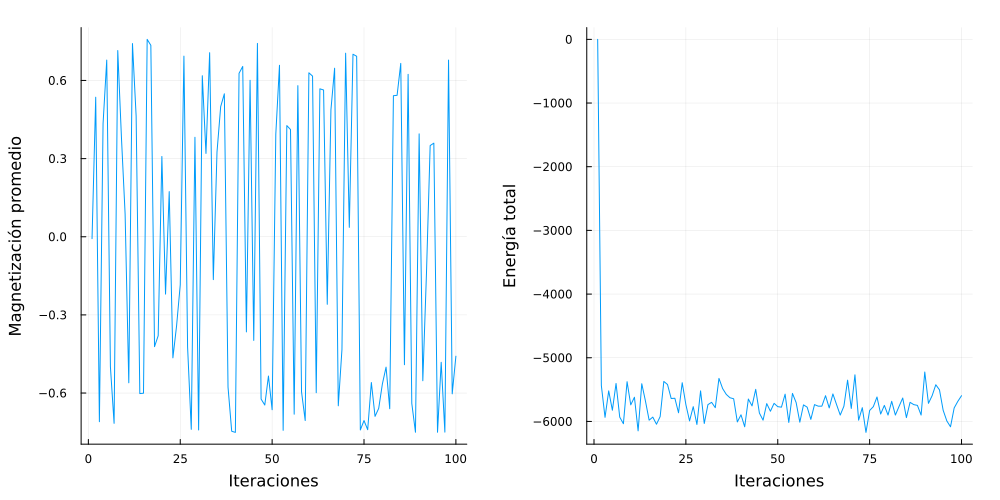

In [23]:
using Plots
using Plots.PlotMeasures

#p_1 = plot(net_spins ./ N^2, xlabel="timesteps", ylabel="Magnetización promedio") #Esta es la magnetización promedio
#p_2 = plot(net_energy, xlabel="timesteps", ylabel="Energía total")

#plot(p_1, p_2, layout=(1, 2), size=(1000, 500), margin=5mm)

net_spins_sub  = (spins ./ N^2)[1:(N^2):end]
net_energy_sub = energy[1:(N^2):end]


p_1 = plot(net_spins_sub,  xlabel="Iteraciones", ylabel="Magnetización promedio", legend=false)
p_2 = plot(net_energy_sub, xlabel="Iteraciones", ylabel="Energía total", legend=false)

plot(p_1, p_2, layout=(1, 2), size=(1000, 500), margin=5mm)